# Município contracts

Contracts whose **adjudicante** name starts with "Município".

**Rule:** after splitting the packed `NIPC - name` field, the name is accent-folded and lowercased
(`normalize_name()`), then matched with `startswith("municipio")`. A naive `starts_with("Município")`
would lose ~3 % of rows (unaccented / uppercase variants such as `MUNICÍPIO DA FIGUEIRA DA FOZ`).

Reference values on the current parquet: **93 516 rows, 309 distinct NIPC** (checked against the data).

Caveats: 309 NIPCs vs 308 real municipalities → at least one false positive
(e.g. `Município de Formação AIRC`). `Câmara Municipal …` names do **not** start with "Município"
and are deliberately excluded (see the near-miss cell).

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import polars as pl
from base_gov.entities import (
    canonical_names,
    entity_key,
    normalize_name,
    split_packed,
)

from base_gov.stats import value_impact, value_per_day

DATA = Path("..") / "data"
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_width_chars(140)
plt.rcParams["figure.figsize"] = (10, 4)

In [2]:
contracts_raw = pl.read_parquet(DATA / "contracts.parquet")
print(f"rows={contracts_raw.height:,}  cols={contracts_raw.width}")


contracts_all = (
    entity_key(
        contracts_raw.with_columns(split_packed("adjudicante", prefix="adjudicante")),
        prefix="adjudicante",
    )
    .select(
        pl.col("idcontrato"),
        pl.col("adjudicante"),
        pl.col("adjudicante_nipc"),
        pl.col("adjudicante_name"),
        pl.col("adjudicante_key"),
        pl.col("adjudicante_key_source"),
        pl.col("adjudicatarios"),
        pl.col("objectoContrato").alias("objecto_contrato"),
        pl.col("precoContratual").alias("preco_contratual"),
        pl.col("prazoExecucao").alias("prazo_execucao"),
        pl.col("dataCelebracaoContrato").alias("data_celebracao"),
        pl.col("CPV").alias("cpv"),
        pl.col("NUTs").alias("nuts"),
        pl.col("Ano").alias("ano"),
        pl.col("tipoContrato").alias("tipo_contrato"),
        pl.col("tipoprocedimento").alias("tipo_procedimento"),
)
)
contracts_all = contracts_all.with_columns(value_per_day())
# Disregard contracts priced below MIN_VALUE (€); contracts_all keeps them for before/after comparisons.
MIN_VALUE = 10
contracts = contracts_all.filter(pl.col("preco_contratual") >= MIN_VALUE)
print(f"disregarded {contracts_all.height - contracts.height:,} contracts with preco_contratual < €{MIN_VALUE} "
      f"({(contracts_all.height - contracts.height) / contracts_all.height:.2%}); kept {contracts.height:,}")
print(f"valor_por_dia defined for {contracts['valor_por_dia'].is_not_null().mean():.1%} of kept contracts "
      f"(needs 1 <= prazo_execucao <= 3650 days)")
contracts.head()

rows=409,344  cols=39
disregarded 1,490 contracts with preco_contratual < €10 (0.36%); kept 407,854
valor_por_dia defined for 98.9% of kept contracts (needs 1 <= prazo_execucao <= 3650 days)


idcontrato,adjudicante,adjudicante_nipc,adjudicante_name,adjudicante_key,adjudicante_key_source,adjudicatarios,objecto_contrato,preco_contratual,prazo_execucao,data_celebracao,cpv,nuts,ano,tipo_contrato,tipo_procedimento,valor_por_dia
i64,str,str,str,str,str,str,str,f64,i64,date,str,str,i64,str,str,f64
11276556,"""506354490 - Freguesia de Moita…","""506354490""","""Freguesia de Moita dos Ferreir…","""506354490""","""nipc""","""503488356 - Barranca - Socieda…","""AQUISIÇÃO DE TOUT-VENANT""",14300.0,327,2025-02-07,"""14210000-6 - Saibro, areia, br…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",43.730887
11394912,"""513606084 - Águas do Norte, S.…","""513606084""","""Águas do Norte, S. A.""","""513606084""","""nipc""","""513718737 - 4ENERGY - Comércio…","""Aquisição de materiais de inst…",336.24,30,2025-03-24,"""38420000-5 - Instrumentos para…","""PT11D - Douro""",2025,"""Aquisição de bens móveis""","""Ao abrigo de acordo-quadro (ar…",11.208
11382226,"""508094461 - Unidade Local de S…","""508094461""","""Unidade Local de Saúde do Alto…","""508094461""","""nipc""","""500626413 - TECNIMEDE- SOCIEDA…","""Medicamentos""",625.25,1,2025-04-17,"""33000000-0 - Equipamento médic…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",625.25
12794466,"""500745471 - Santa Casa da Mise…","""500745471""","""Santa Casa da Misericórdia de …","""500745471""","""nipc""","""504445960 - MBA PORTUGAL, SA""","""Aquisição de material para a c…",22500.0,730,2025-11-27,"""33169000-2 - Material cirúrgic…",null,2025,"""Aquisição de bens móveis""","""Concurso público""",30.821918
11765245,"""508481287 - Unidade Local de S…","""508481287""","""Unidade Local de Saúde de Sant…","""508481287""","""nipc""","""501251685 - ALCON PORTUGAL, LD…","""251G001484/28341-SOLUÇÃO SALIN…",8481.6,123,2025-10-02,"""33690000-3 - Medicamentos vári…",null,2025,"""Aquisição de bens móveis""","""Ajuste Direto Regime Geral""",68.956098


In [3]:
def is_municipio_expr() -> pl.Expr:
    """Accent-folded, lowercased 'municipio' prefix on the adjudicante name."""
    return (
        pl.col("adjudicante_name")
        .map_elements(normalize_name, return_dtype=pl.String)
        .str.starts_with("municipio")
    )


municipio = contracts.filter(is_municipio_expr())
n_entities = municipio["adjudicante_key"].n_unique()
print(f"Município rows: {municipio.height:,}  distinct keys: {n_entities}  "
      f"share of all contracts: {municipio.height / contracts.height:.1%}")
assert 0 < municipio.height < contracts.height


Município rows: 93,330  distinct keys: 309  share of all contracts: 22.9%


In [4]:
# Effect of disregarding contracts priced below €10 on Município contracts.
before = contracts_all.filter(is_municipio_expr())
display(value_impact(before, municipio))

metric,before,after,change,change_pct
str,f64,f64,f64,f64
"""n_contracts""",93516.0,93330.0,-186.0,-0.2
"""mean_value""",90717.819789,90899.044931,181.225142,0.2
"""median_value""",18523.975,18599.92,75.945,0.41
"""total_value""",8.4836e9,8.4836e9,40228.02,0.0


prazo_execucao outside 1..3650 days (excluded from value/day): 1,208 of 93,330


prazo_p10,prazo_p25,prazo_p50,prazo_p75,prazo_p90,eur_dia_p10,eur_dia_p25,eur_dia_p50,eur_dia_p75,eur_dia_p90
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
5.0,30.0,120.0,365.0,730.0,26.76,54.2,231.45,980.0,3558.39


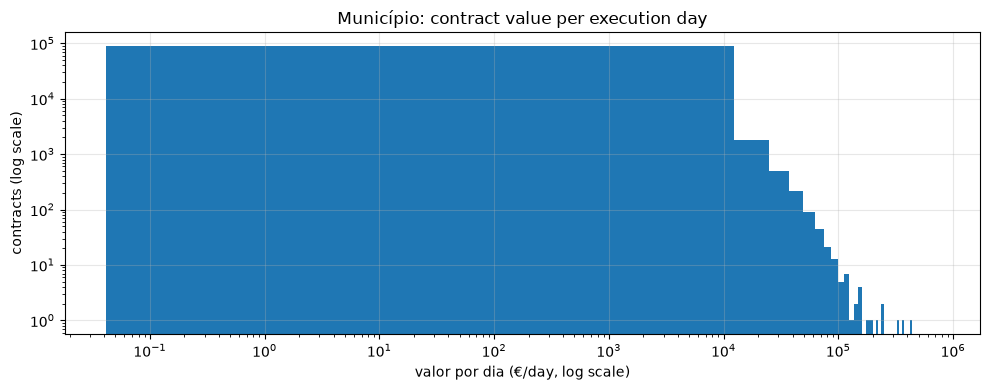

In [5]:
# Execution time (prazo_execucao, days) and value per day. valor_por_dia is null outside 1..3650 days.
d = municipio
print(f"prazo_execucao outside 1..3650 days (excluded from value/day): {d['valor_por_dia'].is_null().sum():,} of {d.height:,}")
display(d.select(
    *[pl.col("prazo_execucao").quantile(q).alias(f"prazo_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
    *[pl.col("valor_por_dia").quantile(q).round(2).alias(f"eur_dia_p{int(q * 100)}") for q in (0.1, 0.25, 0.5, 0.75, 0.9)],
))
vd = d["valor_por_dia"].drop_nulls()
fig, ax = plt.subplots()
ax.hist(vd.filter(vd > 0).to_numpy(), bins=60, log=True)
ax.set_xscale("log")
ax.set_xlabel("valor por dia (€/day, log scale)")
ax.set_ylabel("contracts (log scale)")
ax.set_title("Município: contract value per execution day")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# By duration bucket: how price and price/day move with the contract length.
buckets = (
    municipio.filter(pl.col("valor_por_dia").is_not_null())
    .with_columns(
        pl.when(pl.col("prazo_execucao") <= 30).then(pl.lit("1-30 d"))
        .when(pl.col("prazo_execucao") <= 90).then(pl.lit("31-90 d"))
        .when(pl.col("prazo_execucao") <= 365).then(pl.lit("91-365 d"))
        .otherwise(pl.lit("366-3650 d")).alias("duracao")
    )
    .group_by("duracao")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").median().alias("median_value"),
        pl.col("valor_por_dia").median().round(2).alias("median_eur_per_day"),
        pl.col("preco_contratual").sum().round(0).alias("total_value"),
    )
    .sort("median_value")
)
buckets

duracao,n_contracts,median_value,median_eur_per_day,total_value
str,u32,f64,f64,f64
"""1-30 d""",28049,12202.0,1158.6,6.21326172e8
"""91-365 d""",35528,19134.5,71.83,3.2863e9
"""31-90 d""",14797,21000.0,384.18,7.26511654e8
"""366-3650 d""",13748,38400.0,45.37,3.6850e9


In [7]:
print("adjudicante cells with several entries ('\\n'):", municipio.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height,
      "(whole dataset:", contracts.filter(pl.col("adjudicante").str.contains("\n", literal=True)).height, ")")
print("non-9-digit NIPC:", municipio.filter(pl.col("adjudicante_key_source") != "nipc").height)
print("null preco_contratual:", municipio["preco_contratual"].null_count())
print("null data_celebracao:", municipio["data_celebracao"].null_count())
print("no-NIF ('-') adjudicante rows, whole dataset:", contracts.filter(pl.col("adjudicante_key_source") == "name").height)
print(contracts["adjudicante_key_source"].value_counts(sort=True))


adjudicante cells with several entries ('\n'): 1 (whole dataset: 4 )
non-9-digit NIPC: 1
null preco_contratual: 0
null data_celebracao: 47
no-NIF ('-') adjudicante rows, whole dataset: 2
shape: (2, 2)
┌────────────────────────┬────────┐
│ adjudicante_key_source ┆ count  │
│ ---                    ┆ ---    │
│ str                    ┆ u32    │
╞════════════════════════╪════════╡
│ nipc                   ┆ 407852 │
│ name                   ┆ 2      │
└────────────────────────┴────────┘


In [8]:
# Names containing "munic" that the rule does NOT match (justifies the prefix rule).
near_miss = (
    contracts
    .with_columns(pl.col("adjudicante_name").map_elements(normalize_name, return_dtype=pl.String).alias("norm_name"))
    .filter(pl.col("norm_name").str.contains("munic") & ~pl.col("norm_name").str.starts_with("municipio"))
    .group_by("adjudicante_key")
    .agg(pl.len().alias("n_contracts"))
    .join(canonical_names(contracts, prefix="adjudicante"), on="adjudicante_key", how="left")
    .sort("n_contracts", descending=True)
)
print(f"excluded near-miss rows: {near_miss['n_contracts'].sum():,}")
near_miss.head(15)


excluded near-miss rows: 14,159


adjudicante_key,n_contracts,adjudicante_name
str,u32,str
"""505037700""",916,"""CMPH - DomusSocial - Empresa d…"
"""502017368""",732,"""Autoridade Nacional de Comunic…"
"""501091823""",405,"""Câmara Municipal de Felgueiras"""
"""503541567""",353,"""Gebalis - Gestão do Arrendamen…"
"""680009671""",321,"""Serviços Intermunicipalizados …"
"""500463964""",311,"""Faz Cultura - Empresa Municipa…"
"""507396081""",309,"""EMAC - Empresa Municipal de Am…"
"""680000054""",306,"""Serviços Municipalizados de Ág…"
"""501305912""",304,"""Município de Matosinhos"""


In [9]:
by_entity = (
    municipio
    .group_by("adjudicante_key")
    .agg(
        pl.len().alias("n_contracts"),
        pl.col("preco_contratual").sum().round(2).alias("total_value"),
    )
    .join(canonical_names(municipio, prefix="adjudicante"), on="adjudicante_key", how="left")
)
assert by_entity["n_contracts"].sum() == municipio.height

print("Top 20 municipalities by contract count:")
display(by_entity.sort("n_contracts", descending=True).head(20))
print("\nTop 20 municipalities by total contracted value:")
display(by_entity.sort("total_value", descending=True).head(20))


Top 20 municipalities by contract count:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""500051070""",1735,2.4758e8,"""Município de Lisboa"""
"""500051062""",1487,1.3812e8,"""Município de Sintra"""
"""500745943""",1456,1.9944e8,"""Município de Oeiras"""
"""506663264""",1085,1.1291e8,"""Município de Vila Nova de Fama…"
"""502098139""",1059,1.0550e8,"""Município de Loulé"""
"""501306099""",988,1.1669e8,"""Município do Porto"""
"""505181266""",977,9.4247e7,"""Município de Leiria"""
"""505804786""",929,6.0113e7,"""Município de Vila do Conde"""
"""506901173""",915,1.0315e8,"""Município de Braga"""



Top 20 municipalities by total contracted value:


adjudicante_key,n_contracts,total_value,adjudicante_name
str,u32,f64,str
"""505187531""",809,2.5806e8,"""Município de Cascais"""
"""500051070""",1735,2.4758e8,"""Município de Lisboa"""
"""500745943""",1456,1.9944e8,"""Município de Oeiras"""
"""500051062""",1487,1.3812e8,"""Município de Sintra"""
"""505948605""",698,1.2109e8,"""Município de Guimarães"""
"""501294996""",852,1.2021e8,"""Município de Loures"""
"""501306099""",988,1.1669e8,"""Município do Porto"""
"""505387131""",647,1.1555e8,"""Município da Maia"""
"""504293125""",747,1.1414e8,"""Município de Odivelas"""


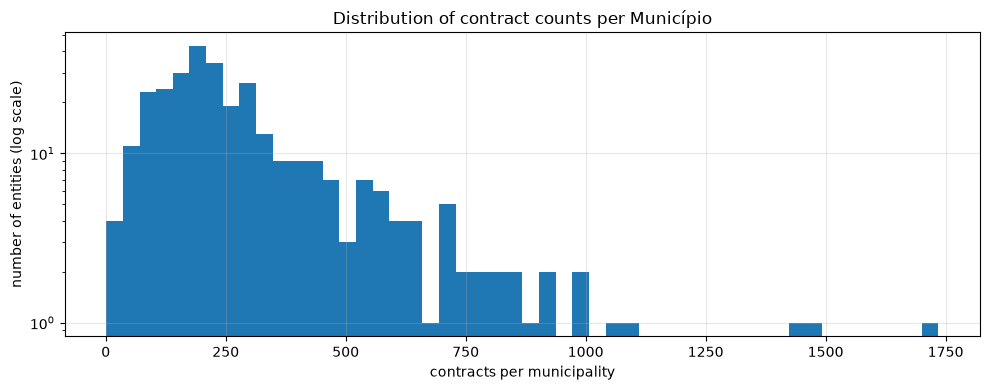

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 309.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 302.038835 │
│ std        ┆ 237.923536 │
│ min        ┆ 1.0        │
│ 25%        ┆ 158.0      │
│ 50%        ┆ 227.0      │
│ 75%        ┆ 370.0      │
│ max        ┆ 1735.0     │
└────────────┴────────────┘


In [10]:
fig, ax = plt.subplots()
ax.hist(by_entity["n_contracts"].to_numpy(), bins=50, log=True)
ax.set_xlabel("contracts per municipality")
ax.set_ylabel("number of entities (log scale)")
ax.set_title("Distribution of contract counts per Município")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
print(by_entity["n_contracts"].describe())


In [11]:
total_value = municipio["preco_contratual"].sum()
print(f"total value: €{total_value / 1e6:,.1f}M  median contract: €{municipio['preco_contratual'].median():,.0f}")
(
    municipio.group_by("tipo_procedimento")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().round(2).alias("total_value"))
    .with_columns(
        (pl.col("n_contracts") / pl.col("n_contracts").sum() * 100).round(1).alias("pct_count"),
        (pl.col("total_value") / pl.col("total_value").sum() * 100).round(1).alias("pct_value"),
    )
    .sort("n_contracts", descending=True)
)


total value: €8,483.6M  median contract: €18,600


tipo_procedimento,n_contracts,total_value,pct_count,pct_value
str,u32,f64,f64,f64
"""Ajuste Direto Regime Geral""",46083,1.0347e9,49.4,12.2
"""Consulta Prévia""",26183,9.7621e8,28.1,11.5
"""Concurso público""",16755,5.2722e9,18.0,62.1
"""Contratação excluída II""",1802,2.2620e8,1.9,2.7
"""Ao abrigo de acordo-quadro (ar…",1045,3.1272e8,1.1,3.7
"""Ao abrigo de acordo-quadro (ar…",1035,2.8590e8,1.1,3.4
"""Consulta Prévia Simplificada""",258,4.0987e7,0.3,0.5
"""Concurso limitado por prévia q…",68,2.5235e8,0.1,3.0
"""Ajuste direto simplificado ao …",47,405500.8,0.1,0.0


In [12]:
print("tipo_contrato:")
display(municipio["tipo_contrato"].value_counts(sort=True).head(15))
print("\nTop 15 CPV:")
display(municipio["cpv"].value_counts(sort=True).head(15))


tipo_contrato:


tipo_contrato,count
str,u32
"""Aquisição de serviços""",56679
"""Aquisição de bens móveis""",22799
"""Empreitadas de obras públicas""",11303
"""Locação de bens móveis""",1682
"""Aquisição de bens móveis Aquis…",565
"""Aquisição de serviços Locação …",124
"""Concessão de serviços públicos""",56
"""Aquisição de bens móveis Locaç…",25
"""Outros""",24



Top 15 CPV:


cpv,count
str,u32
"""98300000-6 - Serviços diversos""",1891
"""92000000-1 - Serviços recreati…",1796
"""79952000-2 - Serviços de event…",1292
"""98390000-3 - Outros serviços""",1265
"""92312240-5 - Serviços prestado…",1231
"""92300000-4 - Serviços recreati…",1110
"""92312100-2 - Serviços recreati…",1054
"""92340000-6 - Serviços de espec…",1028
"""60130000-8 - Serviços de trans…",983


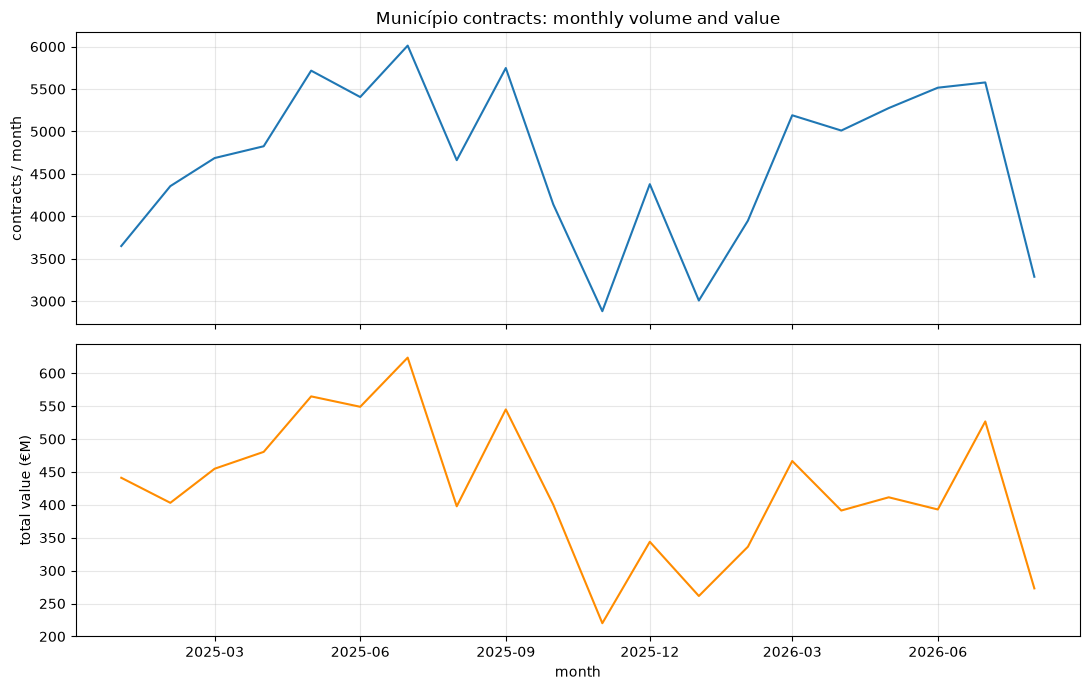

In [13]:
monthly = (
    municipio.filter(pl.col("data_celebracao").is_not_null())
    .with_columns(pl.col("data_celebracao").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .agg(pl.len().alias("n_contracts"), pl.col("preco_contratual").sum().alias("total_value"))
    .sort("month")
)
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
axes[0].plot(monthly["month"], monthly["n_contracts"])
axes[0].set_ylabel("contracts / month")
axes[0].set_title("Município contracts: monthly volume and value")
axes[1].plot(monthly["month"], monthly["total_value"] / 1e6, color="darkorange")
axes[1].set_ylabel("total value (€M)")
axes[1].set_xlabel("month")
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [14]:
municipio.sort("preco_contratual", descending=True, nulls_last=True).select(
    "idcontrato", "adjudicante_name", "preco_contratual", "tipo_procedimento", "data_celebracao", "objecto_contrato"
).head(10)


idcontrato,adjudicante_name,preco_contratual,tipo_procedimento,data_celebracao,objecto_contrato
i64,str,f64,str,date,str
13482357,"""Município de Cascais""",5e7,"""Contratação excluída II""",2026-02-18,"""Promoção da construção, manute…"
13255178,"""Municipio de Vila Real de Sant…",4.4563e7,"""Concurso público""",2025-01-10,"""Empreitada de Reabilitação do …"
15277518,"""Município de Ovar""",3.9700e7,"""Concurso limitado por prévia q…",2026-07-07,"""Aquisição de serviços de recol…"
11603052,"""Município de Vila Nova de Fama…",3.6351e7,"""Concurso limitado por prévia q…",2025-07-17,"""Recolha e Transporte de Resídu…"
11638521,"""Municipio de Vila Real de Sant…",3.39e7,"""Concurso público""",2025-05-19,"""Prestação de Serviços para Rec…"
11393908,"""Município de Lisboa""",3.1147e7,"""Concurso público""",2025-05-05,"""Fornecimento de refeições nas …"
14388020,"""Município de Portimão""",2.6134173e7,"""Concurso público""",2026-03-25,"""CONSTRUÇÃO DE 204 FOGOS  BAIR…"
14842311,"""Município de Cascais""",2.5844e7,"""Concurso público""",2026-05-12,"""Aquisição de serviços de forne…"
14630264,"""Município de Alcobaça""",2.5500e7,"""Concurso limitado por prévia q…",2026-04-21,"""Prestação de serviços para rec…"


## Commentary and limitations

- The matching rule may include false positives (309 NIPCs vs 308 municipalities) and excludes `Câmara Municipal …`.
- `Ano` covers 2025–2026 only: no year-over-year comparison; the first and last months of the monthly series are partial.
- Top-value contracts should be checked as possible outliers or data-entry errors.- Municipalities are keyed by NIPC (`adjudicante_key`); a `-` NIPC would fall back to name similarity.

- Contracts priced below €10 are disregarded; `valor_por_dia` uses only 1–3650-day durations.